# House Prices — So sánh 6 mô hình trên 79 đặc trưng gốc

Dùng cùng cấu hình chia dữ liệu như notebook House Prices ngày 13/11/2026. Mỗi nhà trong `train.csv` được dự đoán đúng một lần khi thuộc fold validation. Xếp hạng theo RMSE trung bình của 5 fold trên `ln(SalePrice)`.

## Tham số

In [1]:
EXPERIMENT_NAME = "14-11-2026_6model_79_phuc"
RANDOM_STATE = 42
N_SPLITS = 5

MODEL_PARAMS = {
    "DummyRegressor": {"strategy": "mean"},
    "Ridge": {"alpha": 1.0, "solver": "lsqr"},
    "Random Forest": {"n_estimators": 200, "min_samples_leaf": 2, "random_state": RANDOM_STATE},
    "Lasso": {"alpha": 0.001, "max_iter": 10000},
    "XGBoost": {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.05,
                "random_state": RANDOM_STATE, "n_jobs": 2},
    "SVR": {"C": 10.0, "epsilon": 0.05, "gamma": "scale"},
}

## Import và tìm thư mục dự án

Kernel cần có `xgboost` hoặc `xgboost-cpu`.

In [2]:
import json
import sys
import warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline

cwd = Path.cwd().resolve()
project = next(
    path for path in (cwd, *cwd.parents, cwd / "Challenge1_House Prices_ Advanced Regression")
    if (path / "src" / "prepare_data.py").is_file()
    and (path / "data" / "raw" / "train.csv").is_file()
)
sys.path.insert(0, str(project))

from src.model import make_lasso, make_svr, make_xgboost
from src.models import make_dummy, make_random_forest, make_ridge
from src.prepare_data import DATA_DIR, ID, TARGET, extract_features, make_preprocessor

## Dữ liệu và các fold

Dùng 79 cột đầu vào gốc, bỏ `Id` và `SalePrice`. Giữ thứ tự hàng trong `train.csv` để tái lập các fold ngày 13/11. Pipeline học cách điền thiếu, chuẩn hóa và mã hóa từ phần train của từng fold.

In [3]:
train = pd.read_csv(DATA_DIR / "raw" / "train.csv")
X = extract_features(train)
prices = train[TARGET]
assert X.shape[1] == 79, f"Cần 79 đặc trưng gốc, hiện có {X.shape[1]}"
assert np.isfinite(prices).all() and prices.gt(0).all()
y = np.log(prices)

cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
splits = list(cv.split(X))
predictions = pd.DataFrame({ID: train[ID], "ln_SalePrice": y})
predictions["fold"] = 0
for fold, (_, valid_idx) in enumerate(splits, 1):
    predictions.loc[valid_idx, "fold"] = fold

display(predictions.groupby("fold").size().rename("Số mẫu validation").to_frame())

,Số mẫu validation
fold,
1,292
2,292
3,292
4,292
5,292


## Huấn luyện và đánh giá

In [4]:
factories = {
    "DummyRegressor": make_dummy,
    "Ridge": make_ridge,
    "Random Forest": make_random_forest,
    "Lasso": make_lasso,
    "XGBoost": make_xgboost,
    "SVR": make_svr,
}

fold_columns = [f"fold{i}" for i in range(1, N_SPLITS + 1)]
metric_rows = []
warning_rows = []
effective_params = {}
for name, factory in factories.items():
    estimator = factory(**MODEL_PARAMS[name])
    effective_params[name] = {key: value for key, value in estimator.get_params().items()
                              if value is not None}
    pipeline = make_pipeline(make_preprocessor(X), estimator)
    scores = []
    predictions[name] = np.nan
    started = perf_counter()
    for fold, (fit_idx, valid_idx) in enumerate(splits, 1):
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            fitted = clone(pipeline).fit(X.iloc[fit_idx], y.iloc[fit_idx])
            predicted = fitted.predict(X.iloc[valid_idx])
        for item in caught:
            warning_rows.append({"model": name, "fold": fold,
                                 "category": item.category.__name__, "message": str(item.message)})
        predictions.loc[valid_idx, name] = predicted
        scores.append(root_mean_squared_error(y.iloc[valid_idx], predicted))

    metric_rows.append({
        "model": name,
        **dict(zip(fold_columns, scores)),
        "rmse_log_mean": np.mean(scores),
        "rmse_log_std": np.std(scores, ddof=1),
        "elapsed_seconds": perf_counter() - started,
    })

results = pd.DataFrame(metric_rows).sort_values("rmse_log_mean", ignore_index=True)
warning_table = pd.DataFrame(warning_rows, columns=["model", "fold", "category", "message"])
assert predictions[list(factories)].notna().all().all()
display(results.round(5))
if not warning_table.empty:
    display(warning_table)

,model,fold1,fold2,fold3,fold4,fold5,rmse_log_mean,rmse_log_std,elapsed_seconds
0,XGBoost,0.13278,0.11839,0.16912,0.13413,0.11311,0.13351,0.02187,5.83956
1,SVR,0.14787,0.15717,0.13535,0.15194,0.12187,0.14284,0.01422,3.15585
2,Lasso,0.13701,0.12349,0.22876,0.11904,0.10978,0.14362,0.04860,1.28237
3,Random Forest,0.14676,0.12849,0.17740,0.14892,0.12276,0.14487,0.02142,17.73768
4,Ridge,0.13393,0.12703,0.22838,0.13340,0.11695,0.14793,0.04549,1.38165
5,DummyRegressor,0.43325,0.39584,0.37537,0.42101,0.36845,0.39878,0.02810,0.94698


## Biểu đồ và nhận xét

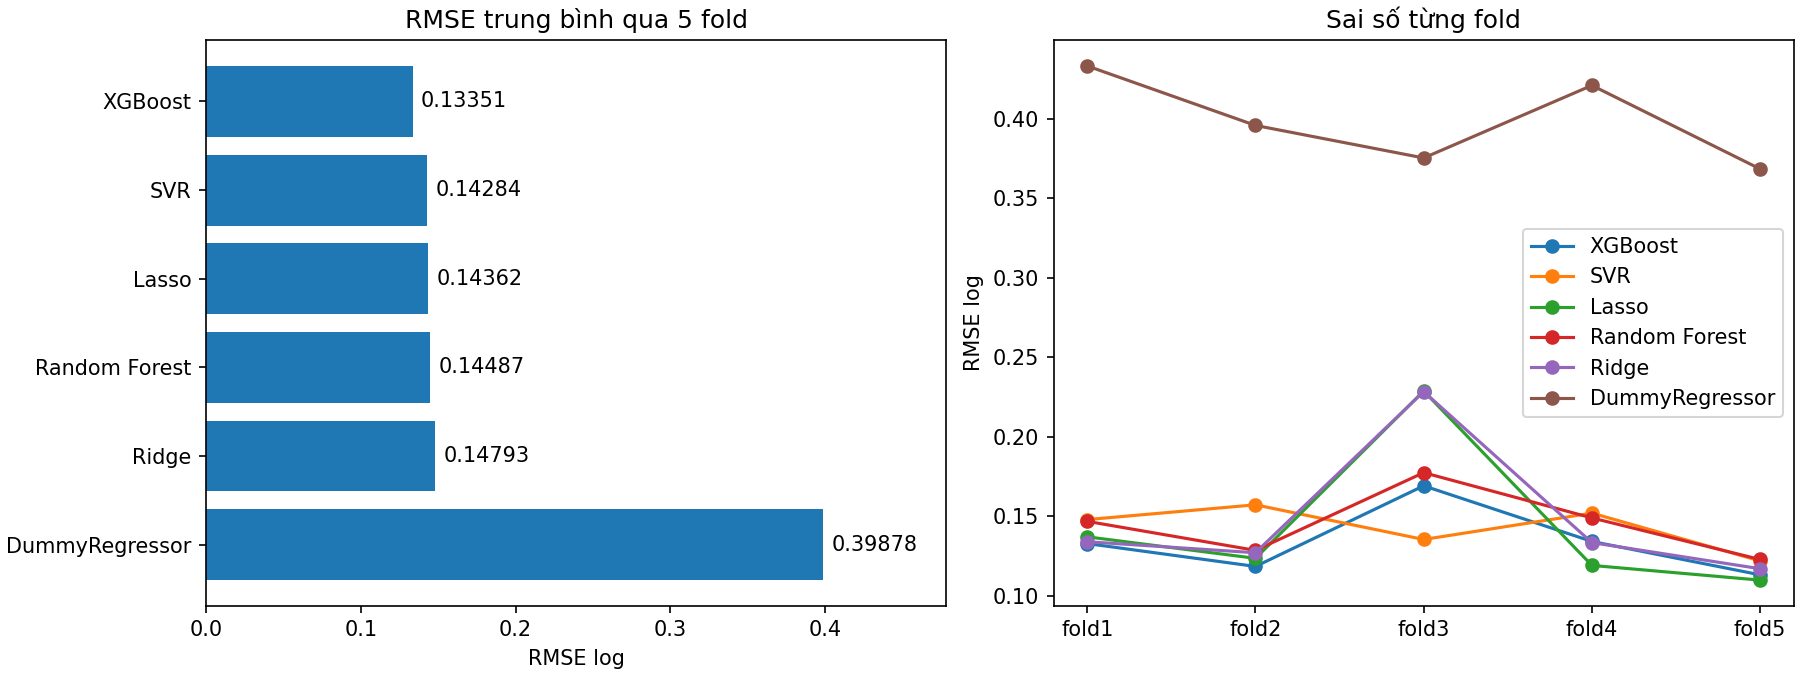

XGBoost có RMSE log trung bình thấp nhất (0.13351), giảm 66.5% so với DummyRegressor.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
axes[0].barh(results["model"], results["rmse_log_mean"])
axes[0].invert_yaxis()
axes[0].bar_label(axes[0].containers[0], fmt="%.5f", padding=4)
axes[0].set(xlabel="RMSE log", title="RMSE trung bình qua 5 fold",
            xlim=(0, results["rmse_log_mean"].max() * 1.2))
for _, row in results.iterrows():
    axes[1].plot(fold_columns, row[fold_columns].to_numpy(dtype=float),
                 marker="o", label=row["model"])
axes[1].set(ylabel="RMSE log", title="Sai số từng fold")
axes[1].legend()
plt.show()

best = results.iloc[0]
baseline = results.set_index("model").loc["DummyRegressor", "rmse_log_mean"]
reduction = 100 * (baseline - best["rmse_log_mean"]) / baseline
print(f"{best['model']} có RMSE log trung bình thấp nhất ({best['rmse_log_mean']:.5f}), "
      f"giảm {reduction:.1f}% so với DummyRegressor.")

## Lưu kết quả

Mỗi lần chạy tạo một thư mục theo thời điểm trong `outputs/`.

In [6]:
run_time = datetime.now(timezone(timedelta(hours=7)))
run_dir = project / "experiments" / EXPERIMENT_NAME / "outputs" / run_time.strftime("%Y%m%d_%H%M%S_%f")
image_dir = run_dir / "img"
image_dir.mkdir(parents=True, exist_ok=False)
results.to_csv(run_dir / "validation_metrics.csv", index=False)
predictions.to_csv(run_dir / "validation_predictions.csv", index=False)
warning_table.to_csv(run_dir / "validation_warnings.csv", index=False)
config = {
    "dataset": "data/raw/train.csv",
    "target_transform": "natural log",
    "feature_columns": X.columns.tolist(),
    "cv": {"n_splits": N_SPLITS, "shuffle": True, "random_state": RANDOM_STATE},
    "model_params": effective_params,
}
(run_dir / "manual_params.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
fig.savefig(image_dir / "6model_rmse_log.png", dpi=150)
print(run_dir.relative_to(project))

experiments\14-11-2026_6model_79_phuc\outputs\20261114_224507_500186
